# 04. Dataset과 DataLoader

실제 데이터는 한 번에 메모리에 올리기 어렵고, 배치 단위로 섞어서 공급해야 합니다. PyTorch는 이를 `Dataset`과 `DataLoader`로 분리합니다.

**학습 목표**
- 커스텀 `Dataset`(`__len__`, `__getitem__`)을 작성한다
- `DataLoader`로 배치, 셔플을 처리하고 `random_split`으로 데이터를 나눈다
- transform을 적용하고, DataLoader로 분류 모델을 학습한다

데이터: `data/samples.csv` (2차원 점 3개 클래스, 나선형 분포)

In [1]:
import torch

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, device: {device}")

PyTorch 2.14.1, device: cpu


## 1. 데이터 준비

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA = Path("data")
csv_path = DATA / "samples.csv"

if not csv_path.exists():
    rng = np.random.default_rng(0)
    n, k = 300, 3   # 클래스당 점 개수, 클래스 수
    rows = []
    for c in range(k):
        r = np.linspace(0.05, 1, n)
        theta = np.linspace(c * 4, (c + 1) * 4, n) + rng.normal(0, 0.2, n)
        rows.append(np.c_[r * np.sin(theta), r * np.cos(theta), np.full(n, c)])
    data = np.vstack(rows)
    DATA.mkdir(exist_ok=True)
    pd.DataFrame(data, columns=["x1", "x2", "label"]).astype({"label": int}).round(4).to_csv(csv_path, index=False)
    print("생성:", csv_path)

df = pd.read_csv(csv_path)
print(df.shape)
print(df["label"].value_counts().sort_index())

생성: data/samples.csv
(900, 3)
label
0    300
1    300
2    300
Name: count, dtype: int64


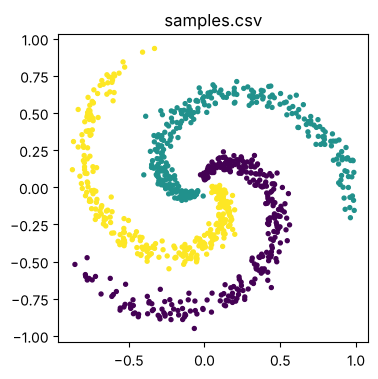

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.scatter(df.x1, df.x2, c=df.label, cmap="viridis", s=8)
plt.title("samples.csv")
plt.show()

## 2. 커스텀 Dataset

`__len__`은 샘플 수를, `__getitem__`은 인덱스에 해당하는 `(입력, 정답)` 한 쌍을 반환합니다.

In [4]:
from torch.utils.data import Dataset

class CsvDataset(Dataset):
    def __init__(self, path, transform=None):
        df = pd.read_csv(path)
        self.x = torch.tensor(df[["x1", "x2"]].values, dtype=torch.float32)
        self.y = torch.tensor(df["label"].values, dtype=torch.long)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.x[idx]
        if self.transform:
            x = self.transform(x)
        return x, self.y[idx]

ds = CsvDataset(csv_path)
print("len:", len(ds))
print("ds[0]:", ds[0])

len: 900
ds[0]: (tensor([0.0013, 0.0500]), tensor(0))


## 3. transform

샘플마다 적용할 전처리를 함수로 넘깁니다. 여기서는 학습용에만 작은 노이즈를 더하는 데이터 증강을 사용합니다.

In [5]:
def add_noise(x, std=0.02):
    return x + std * torch.randn_like(x)

aug_ds = CsvDataset(csv_path, transform=add_noise)
print("원본  :", ds[0][0])
print("증강 1:", aug_ds[0][0])
print("증강 2:", aug_ds[0][0])

원본  : tensor([0.0013, 0.0500])
증강 1: tensor([0.0080, 0.0526])
증강 2: tensor([0.0060, 0.0546])


## 4. 분할과 DataLoader

In [6]:
from torch.utils.data import DataLoader, Subset, random_split

g = torch.Generator().manual_seed(42)
train_split, val_split = random_split(range(len(ds)), [0.8, 0.2], generator=g)

train_ds = Subset(aug_ds, train_split.indices)   # 학습: 증강 적용
val_ds = Subset(ds, val_split.indices)           # 검증: 원본

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=128)

xb, yb = next(iter(train_loader))
print("배치 shape:", xb.shape, yb.shape)
print("학습 배치 수:", len(train_loader), "| 검증 배치 수:", len(val_loader))

배치 shape: torch.Size([32, 2]) torch.Size([32])
학습 배치 수: 23 | 검증 배치 수: 2


## 5. DataLoader로 학습

나선형 데이터는 선형으로 분리되지 않으므로 은닉층이 있는 MLP를 사용합니다.

In [7]:
from torch import nn, optim

model = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 3),
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

def evaluate(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += len(yb)
    return correct / total

for epoch in range(60):
    model.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
    if epoch % 10 == 0 or epoch == 59:
        print(f"epoch {epoch:2d} | loss {running / len(train_ds):.4f} | val acc {evaluate(val_loader):.3f}")

epoch  0 | loss 0.8202 | val acc 0.672


epoch 10 | loss 0.0215 | val acc 0.994


epoch 20 | loss 0.0232 | val acc 1.000


epoch 30 | loss 0.0134 | val acc 1.000


epoch 40 | loss 0.0122 | val acc 1.000


epoch 50 | loss 0.0035 | val acc 1.000


epoch 59 | loss 0.0028 | val acc 1.000


## 6. 결정 경계 시각화

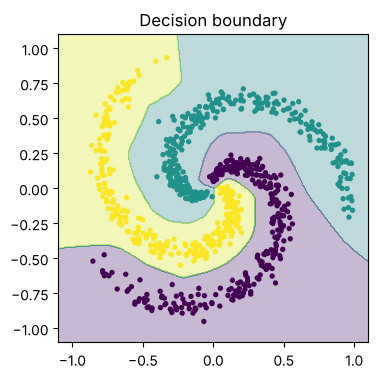

In [8]:
xx, yy = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device)
model.eval()
with torch.no_grad():
    zz = model(grid).argmax(1).cpu().numpy().reshape(xx.shape)

plt.figure(figsize=(4, 4))
plt.contourf(xx, yy, zz, alpha=0.3, cmap="viridis")
plt.scatter(df.x1, df.x2, c=df.label, cmap="viridis", s=8)
plt.title("Decision boundary")
plt.show()

## 요약
- `Dataset`은 "샘플 하나를 어떻게 꺼내는가", `DataLoader`는 "어떻게 배치로 묶어 공급하는가"를 담당한다
- transform으로 샘플 단위 전처리와 증강을 넣는다
- `random_split`/`Subset`으로 학습과 검증을 나누고, 검증에는 증강을 적용하지 않는다